# Wine Quality · K-Means e métricas

Continuação de `eda.ipynb`. A célula abaixo carrega a mesma base combinada de tintos e brancos.

In [1]:
# [IA] Claude – recarga da base para este notebook, com o mesmo código de eda.ipynb.
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

tintos = pd.read_csv("../../data/parte_comum/winequality-red.csv", sep=";")
brancos = pd.read_csv("../../data/parte_comum/winequality-white.csv", sep=";")
tintos["tipo_vinho"] = "tinto"
brancos["tipo_vinho"] = "branco"
vinhos = pd.concat([tintos, brancos], ignore_index=True)

medidas_fisico_quimicas = vinhos.drop(columns=["quality", "tipo_vinho"])
# [IA] Claude – conversão para int, para exibir as notas sem o prefixo np.int64.
classes = [int(nota) for nota in sorted(vinhos["quality"].dropna().unique())]
k_fixo = len(classes)

SAIDA = Path("../../out/parte_comum")
SAIDA.mkdir(parents=True, exist_ok=True)

print(f"Dimensões da base combinada: {vinhos.shape}")
print(f"Notas observadas: {classes} · k da segunda passada: {k_fixo}")

Dimensões da base combinada: (6497, 13)
Notas observadas: [3, 4, 5, 6, 7, 8, 9] · k da segunda passada: 7


## Padronização

O K-Means usa distâncias euclidianas. Antes da padronização, medidas com maior escala, como o dióxido de enxofre total, podem ter mais peso na distância que medidas como o pH. O `StandardScaler` centra as 11 medidas e expressa as diferenças em unidades de desvio padrão. A nota e o tipo de vinho são usados para avaliar e interpretar os grupos após o ajuste.

In [2]:
from sklearn.preprocessing import StandardScaler

padronizador = StandardScaler()

X_padronizado = pd.DataFrame(
    padronizador.fit_transform(medidas_fisico_quimicas),
    columns=medidas_fisico_quimicas.columns,
    index=vinhos.index,
)

print(f"Dimensões dos dados para o K-Means: {X_padronizado.shape}")

display(
    pd.DataFrame({
        "média": X_padronizado.mean(),
        "desvio padrão": X_padronizado.std(ddof=0),
    }).round(4)
)

Dimensões dos dados para o K-Means: (6497, 11)


,média,desvio padrão
fixed acidity,-0.0,1.0
volatile acidity,0.0,1.0
citric acid,0.0,1.0
residual sugar,0.0,1.0
chlorides,0.0,1.0
free sulfur dioxide,-0.0,1.0
total sulfur dioxide,-0.0,1.0
density,-0.0,1.0
pH,0.0,1.0
sulphates,-0.0,1.0


## K-Means e Método do Cotovelo

Ajustamos modelos para `k` de 2 a 10 sobre os mesmos dados padronizados. A inércia é a soma das distâncias quadráticas de cada amostra ao centro do seu grupo. A curva mostra quanto essa soma diminui à medida que acrescentamos grupos.

,inércia
k,
2,56143.9
3,45577.0
4,40721.0
5,38069.2
6,35831.2
7,34054.1
8,32898.2
9,31667.1
10,30589.6


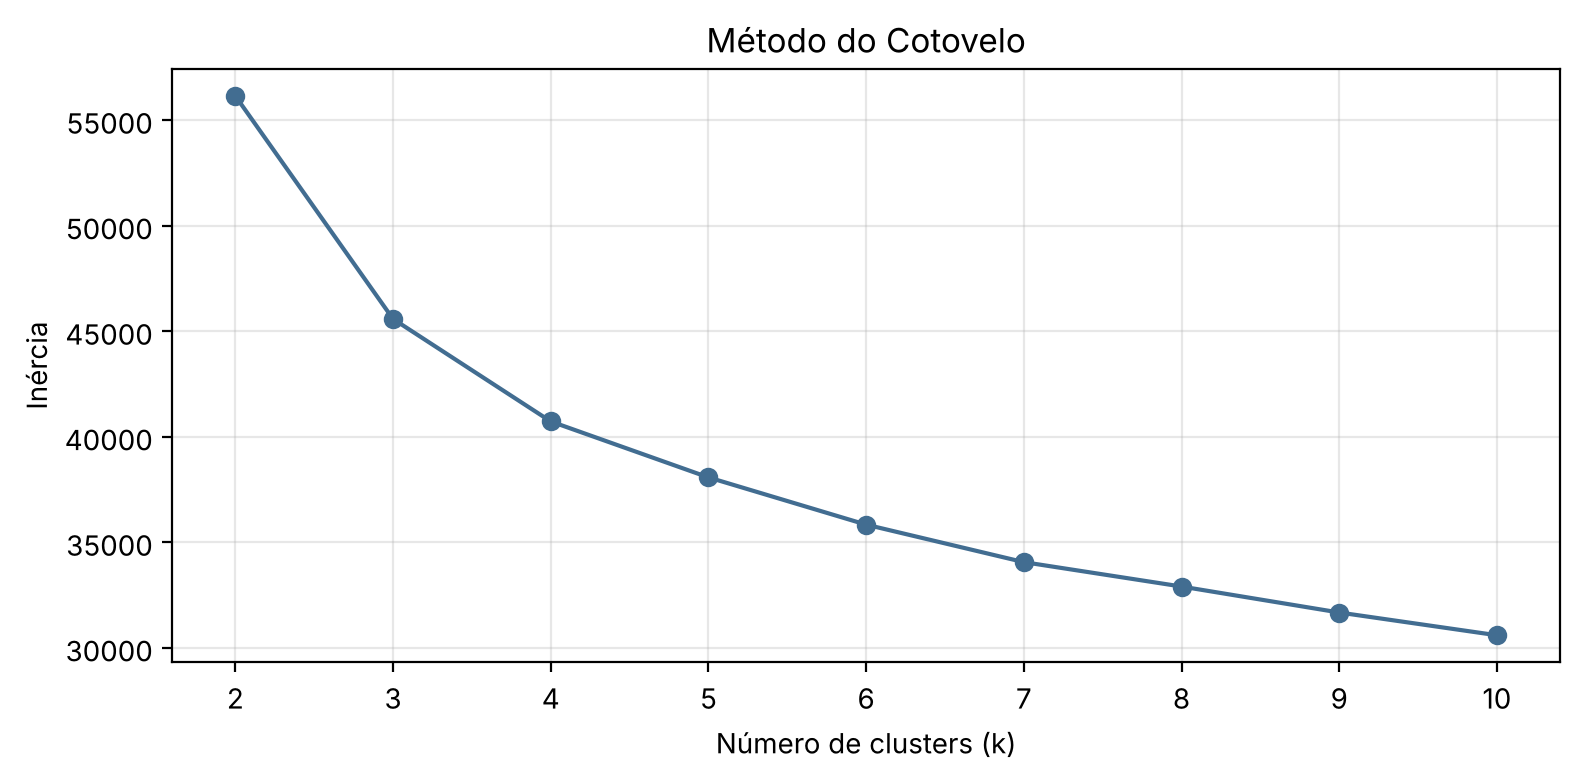

In [3]:
from sklearn.cluster import KMeans

modelos_kmeans = {}
inercia_por_k = {}

for k in range(2, 11):
    modelo = KMeans(n_clusters=k, n_init=10, random_state=42)
    modelo.fit(X_padronizado)

    modelos_kmeans[k] = modelo
    inercia_por_k[k] = modelo.inertia_

cotovelo = pd.Series(inercia_por_k, name="inércia").rename_axis("k")
display(cotovelo.to_frame().round(1))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(cotovelo.index, cotovelo.values, marker="o", color="#426D91")
ax.set_title("Método do Cotovelo")
ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Inércia")
ax.set_xticks(cotovelo.index)
ax.grid(alpha=0.3)

plt.tight_layout()
# [IA] Claude – exportação da figura para out/parte_comum.
fig.savefig(SAIDA / "cotovelo.png", dpi=150, bbox_inches="tight")
plt.show()

Escolhemos **`k = 4`** na primeira passada. A inércia caiu **4.856,0** de três para quatro grupos e **2.651,8** de quatro para cinco. A desaceleração é gradual, o que torna a escolha aproximada. Na segunda passada, usamos **`k = 7`**, o número de notas distintas observadas.

Mostramos as duas passadas nos mesmos eixos do PCA. Eles explicam **50,2%** da variância. A projeção serve para visualizar os resultados, e os grupos foram ajustados nas 11 dimensões padronizadas.

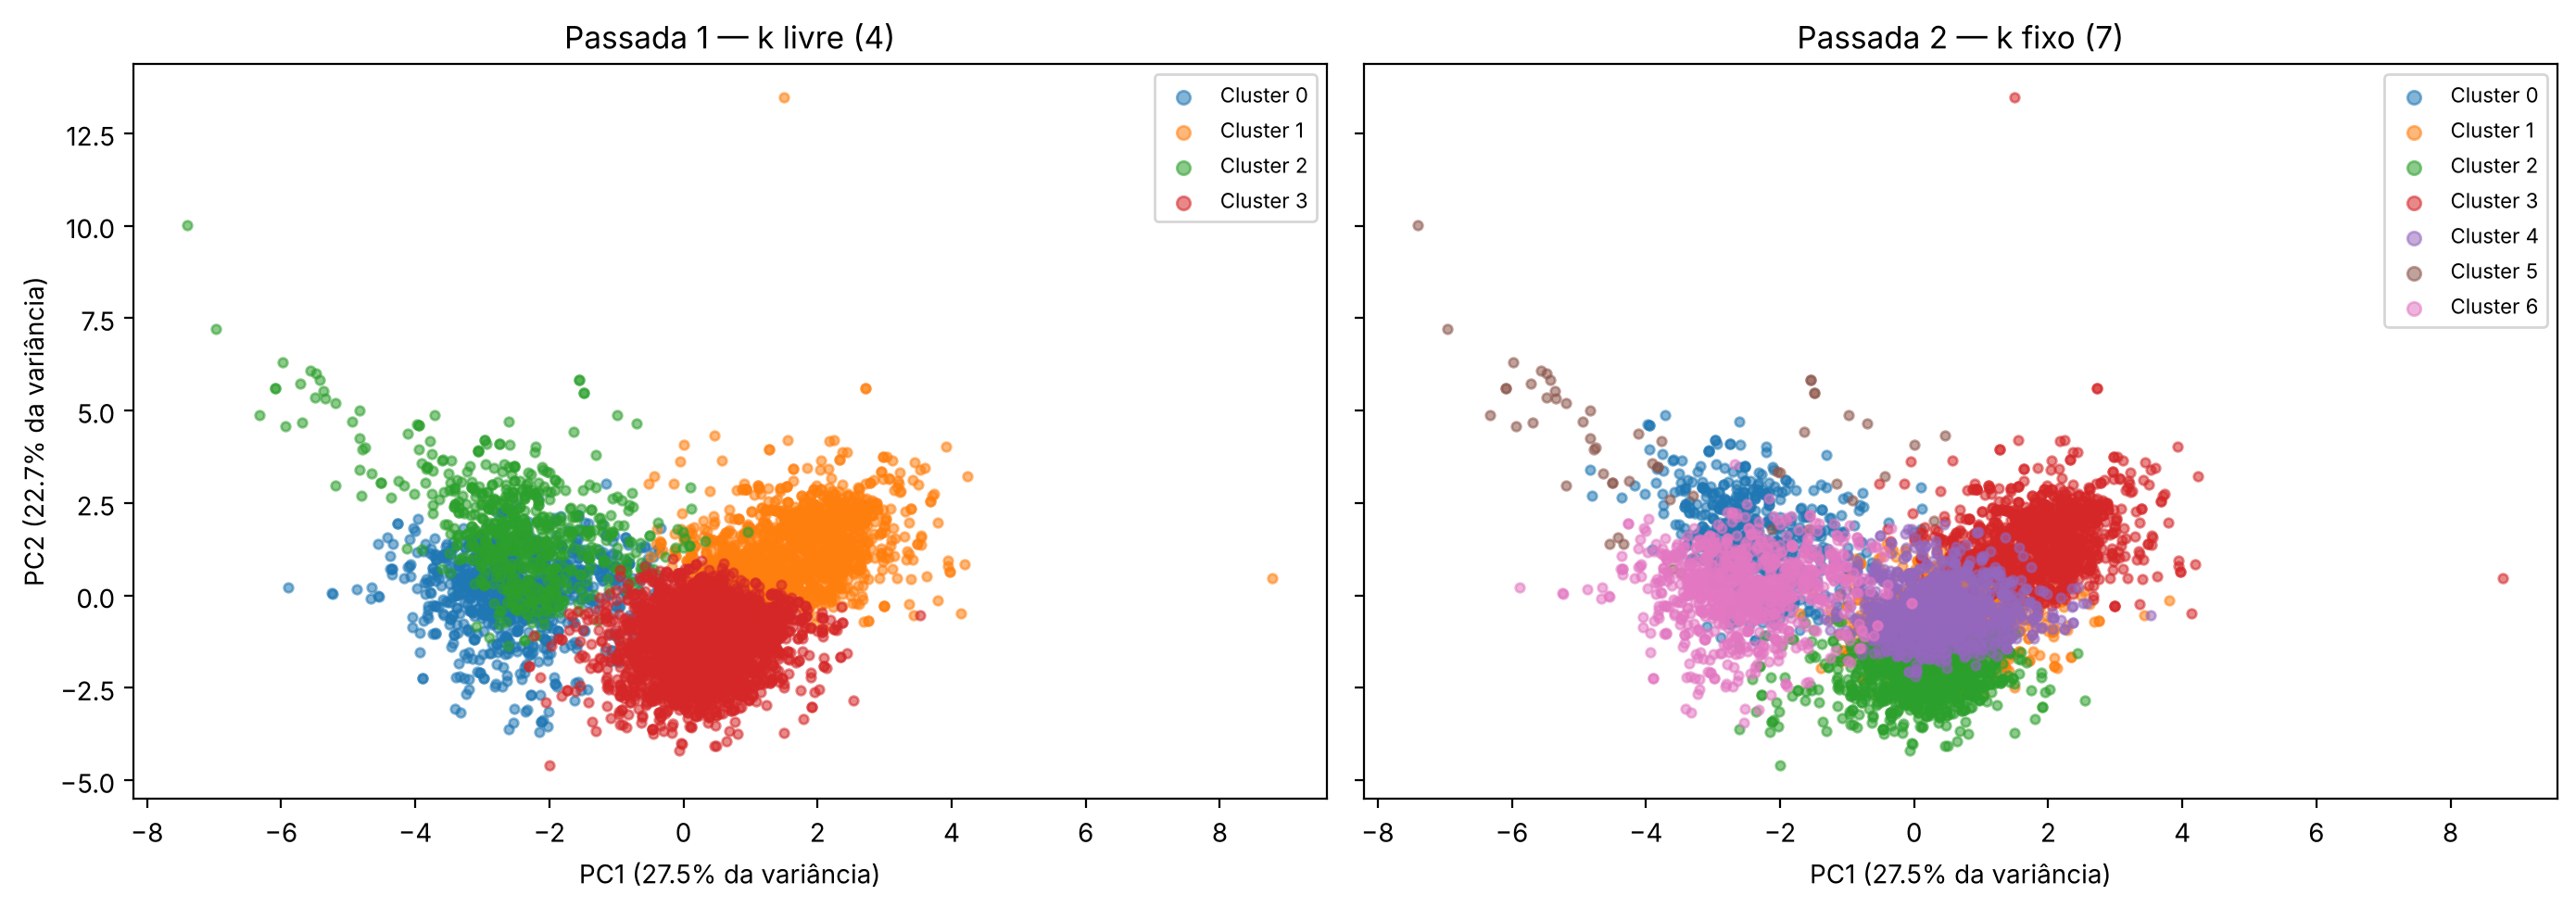

Variância explicada pelos dois eixos: 50.2%


In [4]:
from sklearn.decomposition import PCA

k_livre = 4

modelo_livre = modelos_kmeans[k_livre]
modelo_fixo = modelos_kmeans[k_fixo]

pca = PCA(n_components=2)
coordenadas = pca.fit_transform(X_padronizado)
variancia = pca.explained_variance_ratio_ * 100

fig, eixos = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

passadas = [
    (modelo_livre, f"Passada 1 — k livre ({k_livre})"),
    (modelo_fixo, f"Passada 2 — k fixo ({k_fixo})"),
]

for ax, (modelo, titulo) in zip(eixos, passadas):
    for cluster in range(modelo.n_clusters):
        pertence_ao_cluster = modelo.labels_ == cluster
        ax.scatter(
            coordenadas[pertence_ao_cluster, 0],
            coordenadas[pertence_ao_cluster, 1],
            s=12,
            alpha=0.55,
            label=f"Cluster {cluster}",
        )

    ax.set_title(titulo)
    ax.set_xlabel(f"PC1 ({variancia[0]:.1f}% da variância)")
    ax.legend(fontsize=8, markerscale=1.5)

eixos[0].set_ylabel(f"PC2 ({variancia[1]:.1f}% da variância)")
plt.tight_layout()
# [IA] Claude – exportação da figura para out/parte_comum.
fig.savefig(SAIDA / "passadas_pca.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Variância explicada pelos dois eixos: {variancia.sum():.1f}%")

## Avaliação dos agrupamentos

Cada cluster recebe sua nota real mais frequente. A tabela de contingência cruza **nota real × cluster** e tem dimensões **7 × 4** ou **7 × 7**. Após o mapeamento, as matrizes de confusão são **7 × 7** porque cruzam **nota real × nota atribuída**. Na ausência de atribuições a uma nota, a precisão é indefinida (`NaN`). A silhueta é calculada nas 11 dimensões padronizadas.

Para cada nota, a acurácia um-contra-o-resto é (verdadeiros positivos + verdadeiros negativos) / total de amostras. A acurácia global compara diretamente a nota atribuída com a nota real.


Passada 1 — k livre (4)
Contagem de notas reais por cluster


cluster,0,1,2,3
quality,,,,
3,7,10,5,8
4,71,44,20,81
5,503,797,229,609
6,366,833,285,1352
7,53,157,136,733
8,6,31,12,144
9,0,1,0,4


Tamanho, nota majoritária e tipo de vinho por cluster


tipo_vinho,amostras,nota majoritária,branco (%),tinto (%)
cluster,,,,
0,1006,5,8.8,91.2
1,1873,6,99.8,0.2
2,687,6,7.1,92.9
3,2931,6,98.6,1.4


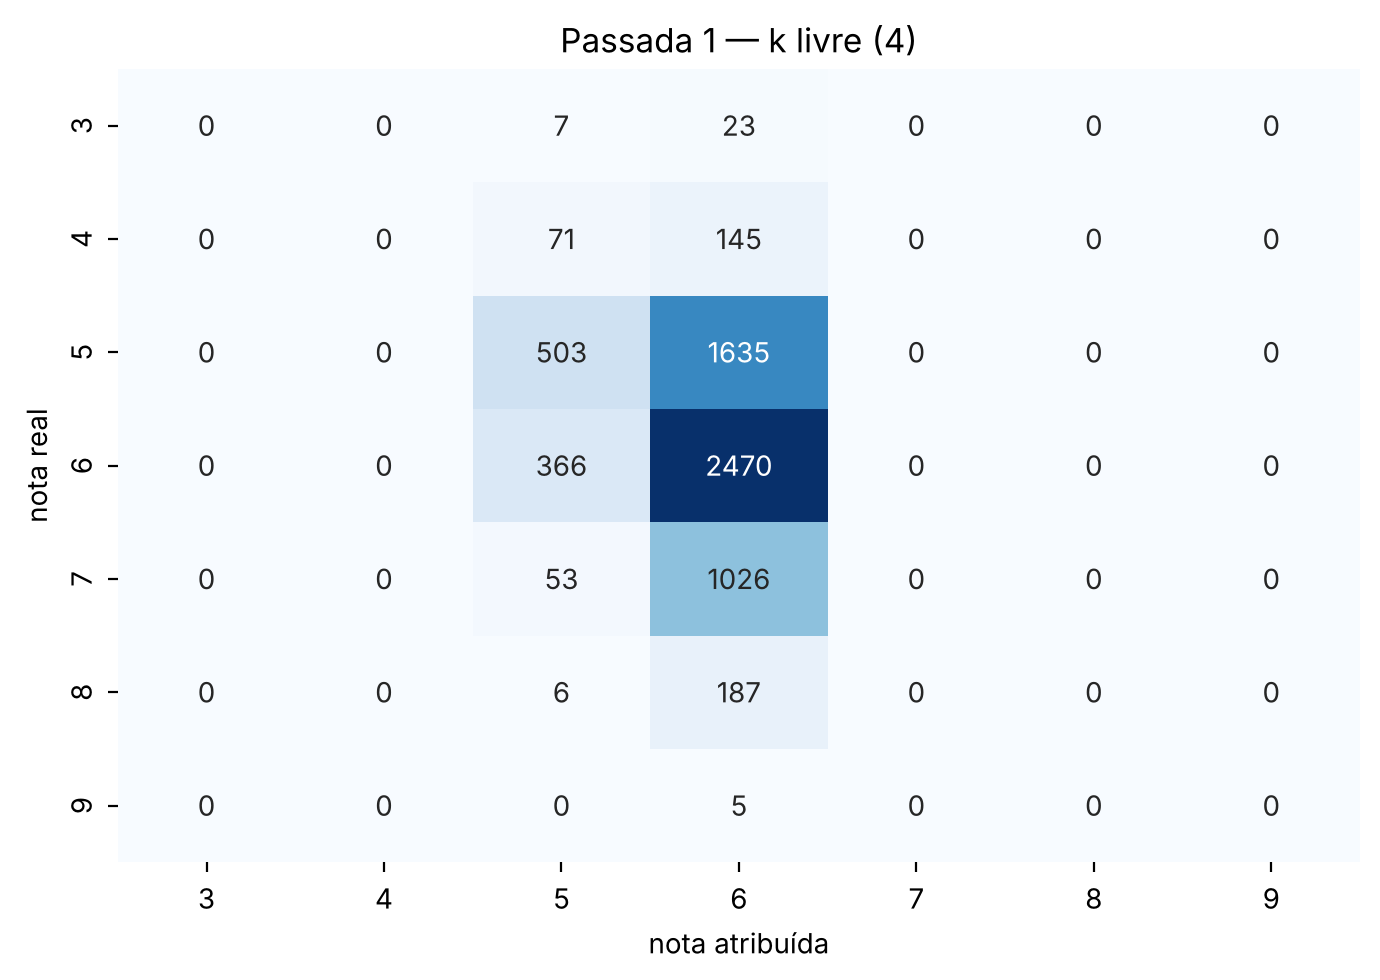

Métricas por nota


,amostras reais,amostras atribuídas,acurácia (1 vs. demais),precisão,recall
3,30,0,0.995,NaN,0.000
4,216,0,0.967,NaN,0.000
5,2138,1006,0.671,0.50,0.235
6,2836,5491,0.479,0.45,0.871
7,1079,0,0.834,NaN,0.000
8,193,0,0.970,NaN,0.000
9,5,0,0.999,NaN,0.000



Passada 2 — k fixo (7)
Contagem de notas reais por cluster


cluster,0,1,2,3,4,5,6
quality,,,,,,,
3,4,2,4,7,5,2,6
4,14,28,20,24,63,2,65
5,182,302,78,650,411,30,485
6,259,505,527,646,536,19,344
7,139,175,454,122,144,2,43
8,12,30,96,21,30,0,4
9,0,0,4,1,0,0,0


Tamanho, nota majoritária e tipo de vinho por cluster


tipo_vinho,amostras,nota majoritária,branco (%),tinto (%)
cluster,,,,
0,610,6,2.3,97.7
1,1042,6,98.1,1.9
2,1183,6,97.3,2.7
3,1471,5,99.9,0.1
4,1189,6,99.3,0.7
5,55,5,18.2,81.8
6,947,5,5.4,94.6


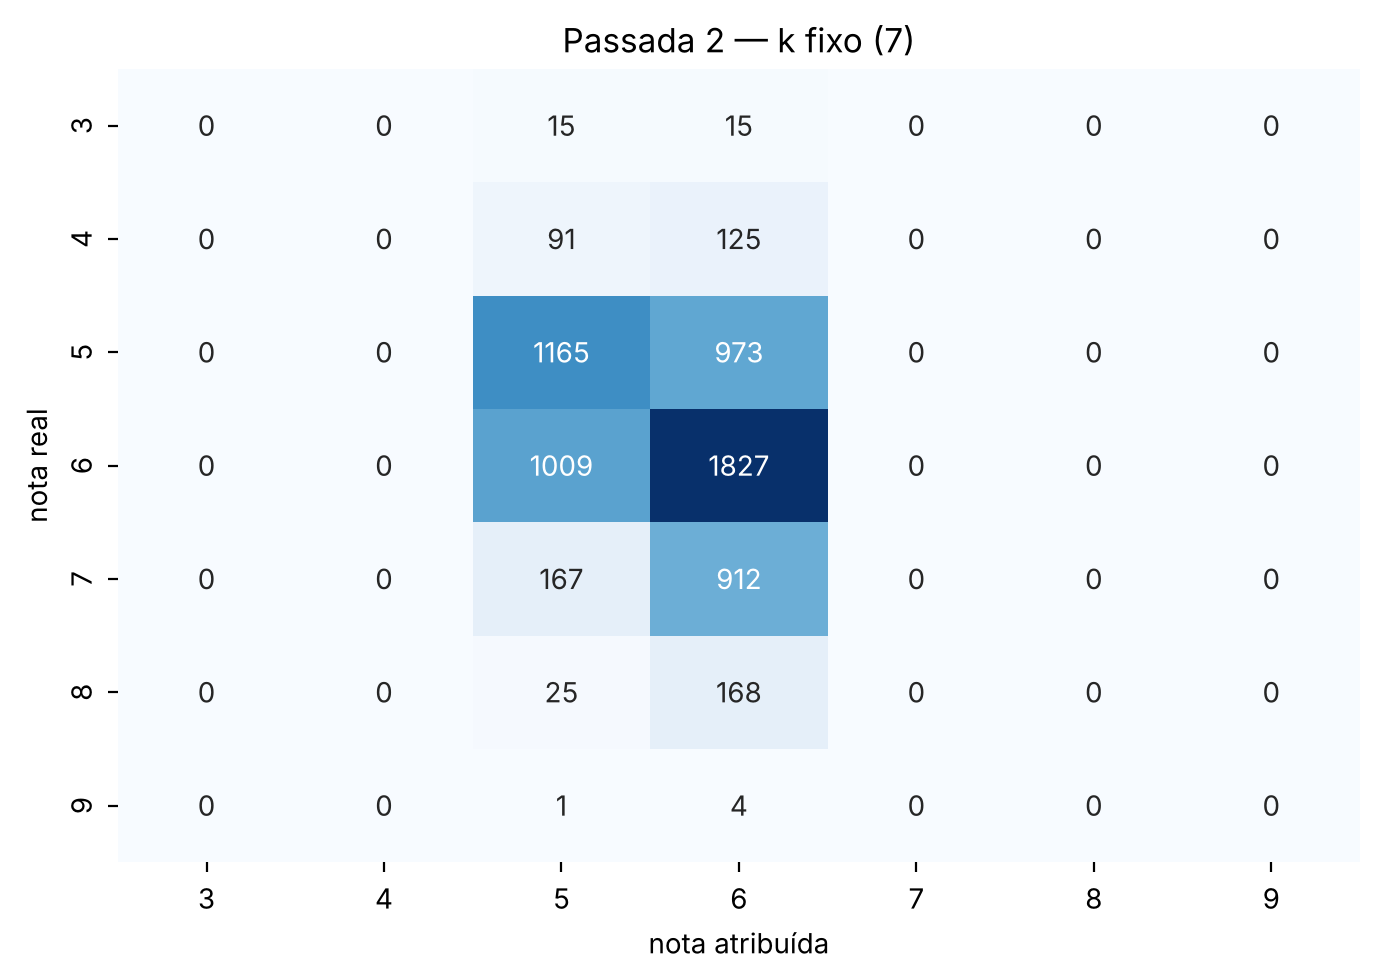

Métricas por nota


,amostras reais,amostras atribuídas,acurácia (1 vs. demais),precisão,recall
3,30,0,0.995,NaN,0.000
4,216,0,0.967,NaN,0.000
5,2138,2473,0.649,0.471,0.545
6,2836,4024,0.507,0.454,0.644
7,1079,0,0.834,NaN,0.000
8,193,0,0.970,NaN,0.000
9,5,0,0.999,NaN,0.000


,acurácia,silhueta
k,,
4,0.458,0.248
7,0.461,0.180


Acurácia de referência ao atribuir sempre a nota 6: 43.7%


In [5]:
from sklearn.metrics import confusion_matrix, silhouette_score

notas_reais = vinhos["quality"]
resultados = []

for modelo, titulo in passadas:
    print(f"\n{titulo}")

    clusters = pd.Series(modelo.labels_, index=vinhos.index, name="cluster")

    # Composição antes do mapeamento: notas reais × clusters.
    notas_por_cluster = pd.crosstab(notas_reais, clusters).reindex(
        index=classes, fill_value=0
    )
    print("Contagem de notas reais por cluster")
    display(notas_por_cluster)

    # Em caso de empate, idxmax escolhe a primeira nota na ordem crescente.
    nota_majoritaria = notas_por_cluster.idxmax(axis=0)
    notas_atribuidas = clusters.map(nota_majoritaria)

    tipo_por_cluster = pd.crosstab(
        clusters, vinhos["tipo_vinho"], normalize="index"
    ).mul(100)

    composicao = tipo_por_cluster.add_suffix(" (%)").round(1)
    composicao.insert(0, "amostras", notas_por_cluster.sum(axis=0))
    composicao.insert(1, "nota majoritária", nota_majoritaria)

    print("Tamanho, nota majoritária e tipo de vinho por cluster")
    display(composicao)

    # Matriz após o mapeamento: notas reais × notas atribuídas.
    matriz = pd.DataFrame(
        confusion_matrix(notas_reais, notas_atribuidas, labels=classes),
        index=pd.Index(classes, name="nota real"),
        columns=pd.Index(classes, name="nota atribuída"),
    )

    plt.figure(figsize=(7, 5))
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(titulo)
    plt.tight_layout()
    # [IA] Claude – exportação da figura para out/parte_comum.
    plt.savefig(SAIDA / f"matriz_confusao_k{modelo.n_clusters}.png", dpi=150, bbox_inches="tight")
    plt.show()

    acertos = pd.Series(matriz.to_numpy().diagonal(), index=classes)
    total_atribuidas = matriz.sum(axis=0)
    total_reais = matriz.sum(axis=1)

    # [IA] Codex – apoio no cálculo e na verificação da acurácia de cada nota contra as demais.
    total = int(matriz.to_numpy().sum())
    verdadeiros_negativos = total - total_reais - total_atribuidas + acertos
    acuracia_por_nota = (acertos + verdadeiros_negativos) / total
    for nota in classes:
        concordancia_binaria = (notas_reais.eq(nota) == notas_atribuidas.eq(nota)).mean()
        assert abs(acuracia_por_nota.loc[nota] - concordancia_binaria) < 1e-12

    metricas = pd.DataFrame({
        "amostras reais": total_reais,
        "amostras atribuídas": total_atribuidas,
        "acurácia (1 vs. demais)": acuracia_por_nota,
        "precisão": acertos.div(total_atribuidas.where(total_atribuidas.gt(0))),
        "recall": acertos.div(total_reais),
    })

    print("Métricas por nota")
    display(metricas.round(3))

    resultados.append({
        "k": modelo.n_clusters,
        "acurácia": acertos.sum() / len(vinhos),
        "silhueta": silhouette_score(X_padronizado, clusters),
    })

comparacao = pd.DataFrame(resultados).set_index("k")
display(comparacao.round(3))

referencia = notas_reais.value_counts(normalize=True).max()
print(f"Acurácia de referência ao atribuir sempre a nota 6: {referencia:.1%}")

## Discussão crítica e conclusão

| Indicador | k = 4 | k = 7 |
|---|---:|---:|
| Silhueta | 0,248 | 0,180 |
| Acurácia após o mapeamento | 45,8% | 46,1% |
| Precisão da nota 5 | 50,0% | 47,1% |
| Recall da nota 5 | 23,5% | 54,5% |
| Precisão da nota 6 | 45,0% | 45,4% |
| Recall da nota 6 | 87,1% | 64,4% |

**Coerência dos grupos.** Entre as duas passadas, quatro clusters apresentaram a maior silhueta, sinal de melhor compactação e separação relativas nas medidas usadas. Com sete clusters, houve apenas 19 coincidências adicionais entre notas reais e atribuídas. Ambas as acurácias ficaram próximas dos 43,7% obtidos ao atribuir sempre a nota 6. A acurácia mede concordância na base analisada, pois os rótulos reais são usados após o ajuste para mapear os clusters.

**Tipo de vinho.** Com quatro clusters, dois tinham mais de 91% de tintos e os outros dois tinham mais de 98% de brancos. Com sete clusters, o predomínio de um tipo por grupo também foi observado. Isso é compatível com as diferenças entre tintos e brancos encontradas na EDA.

**Granularidade das notas.** As duas passadas atribuíram apenas as notas 5 e 6. As notas 3, 4, 7, 8 e 9 tiveram recall zero porque nenhuma foi a mais frequente dentro de um cluster. Com sete clusters, um deles reuniu **650 vinhos de nota 5 e 646 de nota 6**, recebendo a nota 5 por uma diferença de quatro amostras. Esse exemplo, junto com a sobreposição dos boxplots, indica que as notas 5 e 6 são difíceis de separar com o método e as medidas usados. Uma proposta de fusão precisaria de evidências adicionais, como verificar se a sobreposição persiste dentro de cada tipo de vinho.